# **Connect to GEE**

In [ ]:
!pip install -q --upgrade --pre xee
!pip install -q -U geemap

In [ ]:
import ee

In [ ]:
ee.Authenticate()
ee.Initialize(
    project = 'ee-amirhosseinahrari',
    opt_url = 'https://earthengine-highvolume.googleapis.com'
)

# **Study Area**

In [ ]:
import geemap

In [ ]:
map = geemap.Map(basemap = 'SATELLITE')
map

Map(center=[0, 0], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', transp…

In [ ]:
point = map.draw_last_feature.geometry()
point

ee.Geometry({
  "functionInvocationValue": {
    "functionName": "Feature.geometry",
    "arguments": {
      "feature": {
        "functionInvocationValue": {
          "functionName": "Feature",
          "arguments": {
            "geometry": {
              "functionInvocationValue": {
                "functionName": "GeometryConstructors.Point",
                "arguments": {
                  "coordinates": {
                    "constantValue": [
                      52.558594,
                      34.089061
                    ]
                  }
                }
              }
            }
          }
        }
      }
    }
  }
})

In [ ]:
border = (
    ee.FeatureCollection("USDOS/LSIB_SIMPLE/2017")
    .filterBounds(point)
    .geometry()
)

In [ ]:
map.addLayer(border, {},'border')

# **ERA5 Image Collection**

In [ ]:
era = (
    ee.ImageCollection("ECMWF/ERA5_LAND/MONTHLY_AGGR")
    .filterDate('2000','2025')
    .select('total_precipitation_sum')
)

era

# **to Xarray**

In [ ]:
from xee import helpers
from shapely.geometry import shape
import xarray as xr

In [ ]:
grid = helpers.fit_geometry(
    geometry = shape(border.getInfo()),
    grid_crs = 'EPSG:4326',
    grid_scale = (0.5, -0.5)
)

In [ ]:
ds = xr.open_dataset(
    era,
    engine = 'ee',
    **grid
)

In [ ]:
ds = ds.sortby('time') * 1000

# **SPI**

In [ ]:
!pip install -q xclim

In [ ]:
from xclim.indicators.atmos import standardized_precipitation_index

In [ ]:
help(standardized_precipitation_index)

Help on SPI in module xclim.core.indicator:

<xclim.core.indicator.SPI object>
    Standardized Precipitation Index (SPI) (realm: atmos)

    Precipitation over a moving window, normalized such that SPI averages to 0 for the calibration data. The window unit `X` is the minimal time period defined by the resampling frequency.

    This indicator will check for missing values according to the method "from_context".
    Based on indice :py:func:`~xclim.indices._agro.standardized_precipitation_index`.
    Keywords :  precipitation.

    Parameters
    ----------
    pr : str or DataArray
        Daily precipitation.
        Default : `ds.pr`. [Required units : [precipitation]]
    freq : offset alias (string)
        Resampling frequency. A monthly or daily frequency is expected. Option `None` assumes that the desired resampling has already been applied input dataset and will skip the resampling step. See https://pandas.pydata.org/pandas-docs/stable/user_guide/timeseries.html#offset-aliase

In [ ]:
ds.total_precipitation_sum.attrs['units']= 'mm/month'

In [ ]:
spi = standardized_precipitation_index(
    ds.total_precipitation_sum,
    freq = 'MS',
    window = 12
)

# **Clipping**

In [ ]:
border_gdf = geemap.ee_to_gdf(ee.FeatureCollection(border))

In [ ]:
!pip install -q rioxarray
import rioxarray

In [ ]:
spi_proj = spi.rio.write_crs('EPSG:4326')

In [ ]:
spi_clip = spi_proj.rio.clip(border_gdf.geometry, border_gdf.crs)

In [ ]:
spi_annual = spi_clip.resample(time = 'YE').mean('time')

In [ ]:
import matplotlib.pyplot as plt

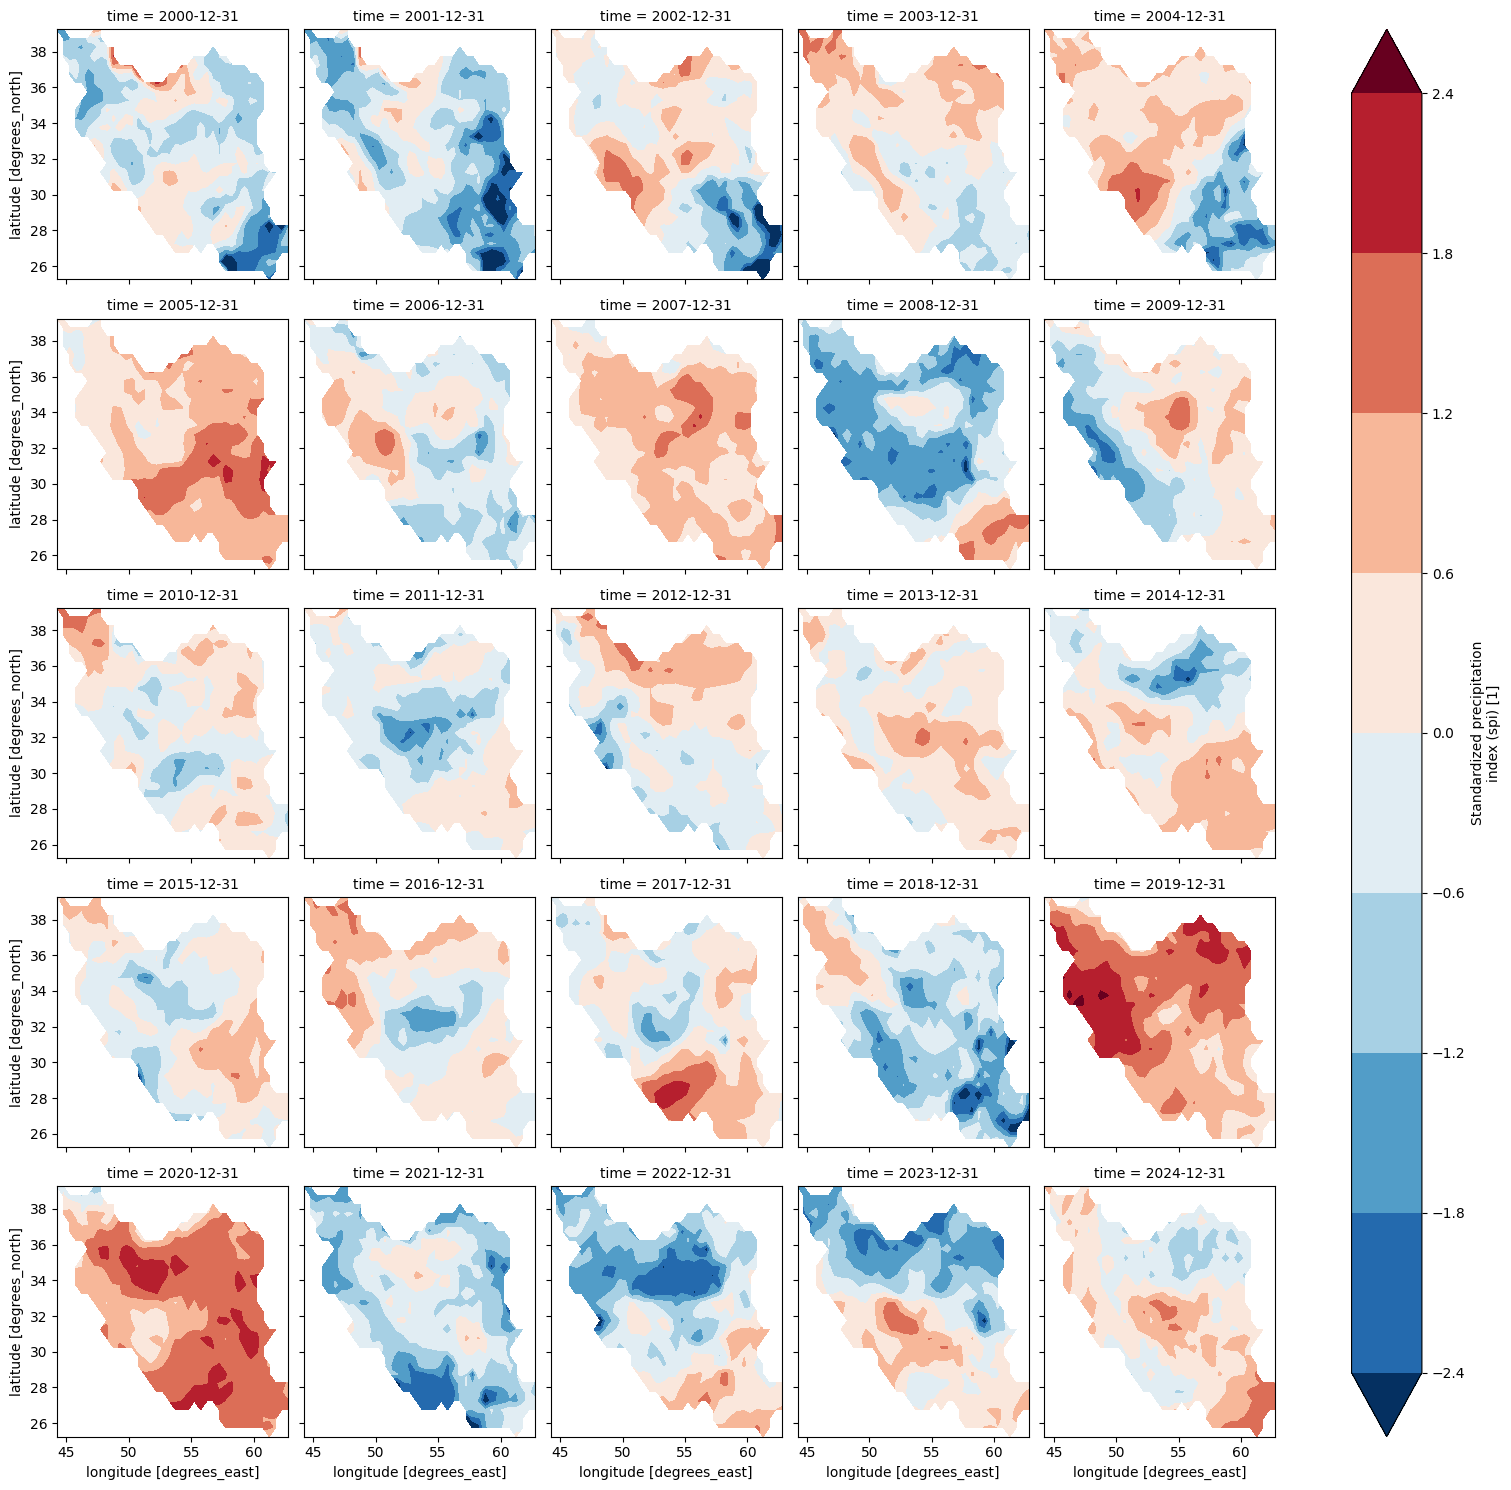

In [ ]:
spi_annual.plot.contourf(
    robust = True,
    col = 'time',
    col_wrap = 5,
    levels = 8
)

plt.savefig('spi_annual.png', dpi = 360, bbox_inches ='tight')

In [ ]:
spi_point = spi_clip.sel(
    x = 46.04097867901053,
    y = 36.978389102457506,
    method = 'nearest'
)

In [ ]:
df = spi_point.to_dataframe()['spi']

In [ ]:
dry = df[df < 0]
wet = df[df >= 0]

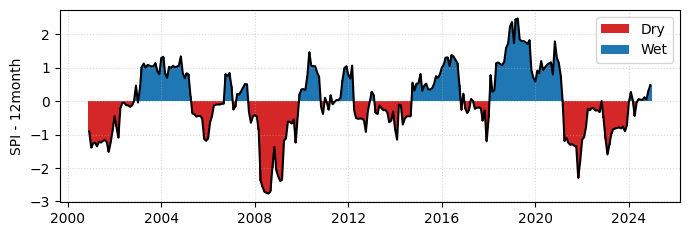

In [ ]:
fig, ax = plt.subplots(figsize = (8,2.5))

ax.bar(dry.index, dry, width = 40, color = 'tab:red', label = 'Dry')
ax.bar(wet.index, wet, width = 40, color = 'tab:blue', label = 'Wet')
ax.plot(df.index, df, color = 'black')
ax.legend()
ax.set_ylabel('SPI - 12month')
ax.grid(ls = ':', alpha = 0.5)

plt.savefig('spi_point.png', dpi = 360, bbox_inches = 'tight')